# AI Assistant Usage in Student Life: Analysis & Reuse Prediction

**Goal:** understand how students use AI assistants (session length, prompts, task type, level of AI help, outcome, satisfaction) and test what, if anything, predicts whether a student **uses the assistant again** (`UsedAgain`).

**Data:** 10,000 sessions, 11 columns (student level, discipline, task type, session length, prompts, AI assistance level, final outcome, satisfaction, reuse).

## Key findings
*(computed at the end of the notebook, see "Conclusions")*

## 1. Load data and quality checks

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
SEED = 42

df = pd.read_csv("data/ai_assistant_usage_student_life.csv", parse_dates=["SessionDate"])
df["UsedAgain"] = df["UsedAgain"].astype(int)
print(df.shape)
df.head()

(10000, 11)


,SessionID,StudentLevel,Discipline,SessionDate,SessionLengthMin,TotalPrompts,TaskType,AI_AssistanceLevel,FinalOutcome,UsedAgain,SatisfactionRating
0,SESSION00001,Undergraduate,Computer Science,2024-11-03,31.20,11,Studying,2,Assignment Completed,1,1.0
1,SESSION00002,Undergraduate,Psychology,2024-08-25,13.09,6,Studying,3,Assignment Completed,1,2.0
2,SESSION00003,Undergraduate,Business,2025-01-12,19.22,5,Coding,3,Assignment Completed,1,3.3
3,SESSION00004,Undergraduate,Computer Science,2025-05-06,3.70,1,Coding,3,Assignment Completed,1,3.5
4,SESSION00005,Undergraduate,Psychology,2025-03-18,28.12,9,Writing,3,Assignment Completed,1,2.9


In [2]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", df.duplicated().sum(), "| duplicate SessionIDs:", df["SessionID"].duplicated().sum())
print("Date range:", df["SessionDate"].min().date(), "to", df["SessionDate"].max().date())
base_rate = df["UsedAgain"].mean()
print(f"\nReuse rate: {base_rate:.1%}  ->  a model that ALWAYS predicts 'will reuse' is already {base_rate:.1%} accurate (majority baseline)")
df.describe().round(2)

Missing values: 0
Duplicate rows: 0 | duplicate SessionIDs: 0
Date range: 2024-06-24 to 2025-06-24

Reuse rate: 70.6%  ->  a model that ALWAYS predicts 'will reuse' is already 70.6% accurate (majority baseline)


,SessionDate,SessionLengthMin,TotalPrompts,AI_AssistanceLevel,UsedAgain,SatisfactionRating
count,10000,10000.00,10000.00,10000.00,10000.00,10000.00
mean,2024-12-23 09:05:36.960000,19.85,5.61,3.48,0.71,3.42
min,2024-06-24 00:00:00,0.03,1.00,1.00,0.00,1.00
25%,2024-09-20 00:00:00,9.63,2.00,3.00,0.00,2.60
50%,2024-12-25 00:00:00,16.65,4.00,4.00,1.00,3.50
75%,2025-03-27 00:00:00,26.67,8.00,4.00,1.00,4.40
max,2025-06-24 00:00:00,110.81,39.00,5.00,1.00,5.00
std,NaN,13.90,4.65,0.99,0.46,1.14


## 2. Outlier handling: why I did **not** remove them

A common approach is to drop IQR "outliers" from every numeric column. Here that is wrong for two reasons, which I check below:

- `AI_AssistanceLevel` and `SatisfactionRating` are bounded 1-5 **rating scales**, so a rating of 1 is a valid answer, not an error.
- Session length and prompt counts have a natural long tail (a few long sessions are real behaviour).

I measure what the IQR rule would have deleted.

In [3]:
def iqr_mask(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s > q1 - 1.5 * iqr) & (s < q3 + 1.5 * iqr)

cols = ["SessionLengthMin", "TotalPrompts", "AI_AssistanceLevel", "SatisfactionRating"]
tmp = df.copy()
for c in cols:
    before = len(tmp); tmp = tmp[iqr_mask(tmp[c])]
    print(f"{c:20s} removes {before - len(tmp):4d} rows")
print(f"\nTotal lost: {len(df) - len(tmp)} rows ({1 - len(tmp)/len(df):.1%})")
print("\nAI_AssistanceLevel counts  original vs after IQR removal:")
print(pd.concat([df["AI_AssistanceLevel"].value_counts().sort_index().rename("original"),
                 tmp["AI_AssistanceLevel"].value_counts().sort_index().rename("after_IQR")], axis=1))

SessionLengthMin     removes  302 rows
TotalPrompts         removes  328 rows
AI_AssistanceLevel   removes  231 rows
SatisfactionRating   removes    0 rows

Total lost: 861 rows (8.6%)

AI_AssistanceLevel counts  original vs after IQR removal:
                    original  after_IQR
AI_AssistanceLevel                     
1                        241        NaN
2                       1356     1263.0
3                       3361     3136.0
4                       3451     3251.0
5                       1591     1489.0


The IQR rule wipes out **every single** `AI_AssistanceLevel = 1` session (the whole lowest level of the scale disappears) plus ~8.6% of all rows, which biases the data. So the dataset is kept intact.

## 3. Exploratory analysis

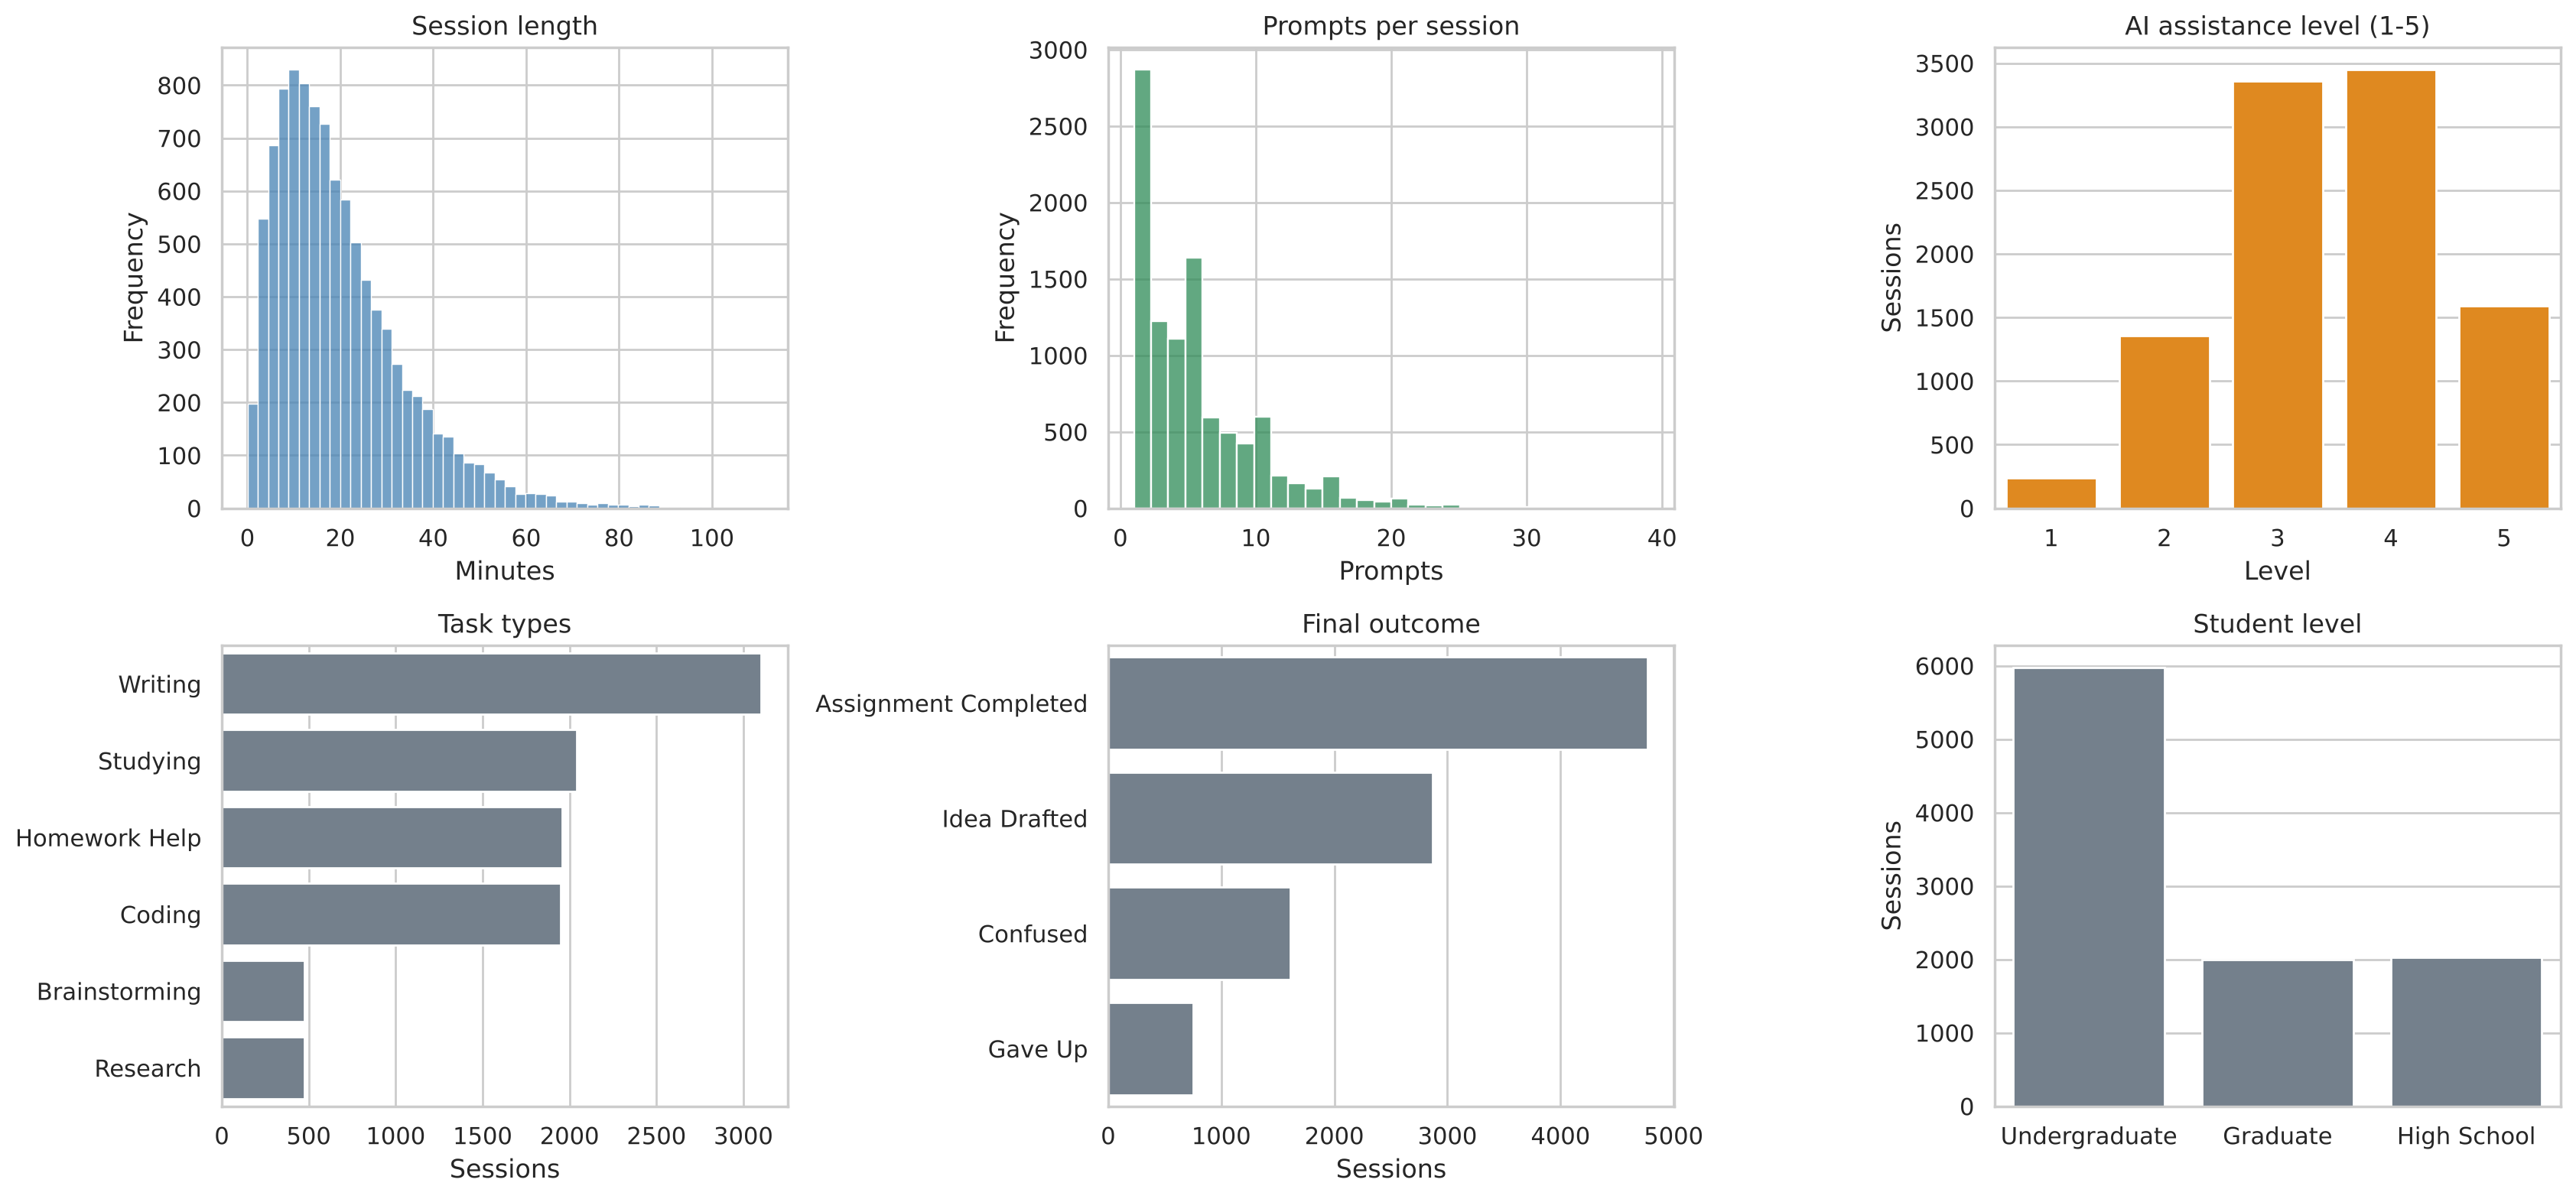

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
sns.histplot(df["SessionLengthMin"], bins=50, ax=axes[0, 0], color="steelblue"); axes[0, 0].set(title="Session length", xlabel="Minutes", ylabel="Frequency")
sns.histplot(df["TotalPrompts"], bins=30, ax=axes[0, 1], color="seagreen"); axes[0, 1].set(title="Prompts per session", xlabel="Prompts", ylabel="Frequency")
sns.countplot(x="AI_AssistanceLevel", data=df, ax=axes[0, 2], color="darkorange"); axes[0, 2].set(title="AI assistance level (1-5)", xlabel="Level", ylabel="Sessions")
order = df["TaskType"].value_counts().index
sns.countplot(y="TaskType", data=df, order=order, ax=axes[1, 0], color="slategray"); axes[1, 0].set(title="Task types", xlabel="Sessions", ylabel="")
sns.countplot(y="FinalOutcome", data=df, order=df["FinalOutcome"].value_counts().index, ax=axes[1, 1], color="slategray"); axes[1, 1].set(title="Final outcome", xlabel="Sessions", ylabel="")
sns.countplot(x="StudentLevel", data=df, ax=axes[1, 2], color="slategray"); axes[1, 2].set(title="Student level", xlabel="", ylabel="Sessions")
plt.tight_layout(); plt.show()

### 3.1 What drives satisfaction?

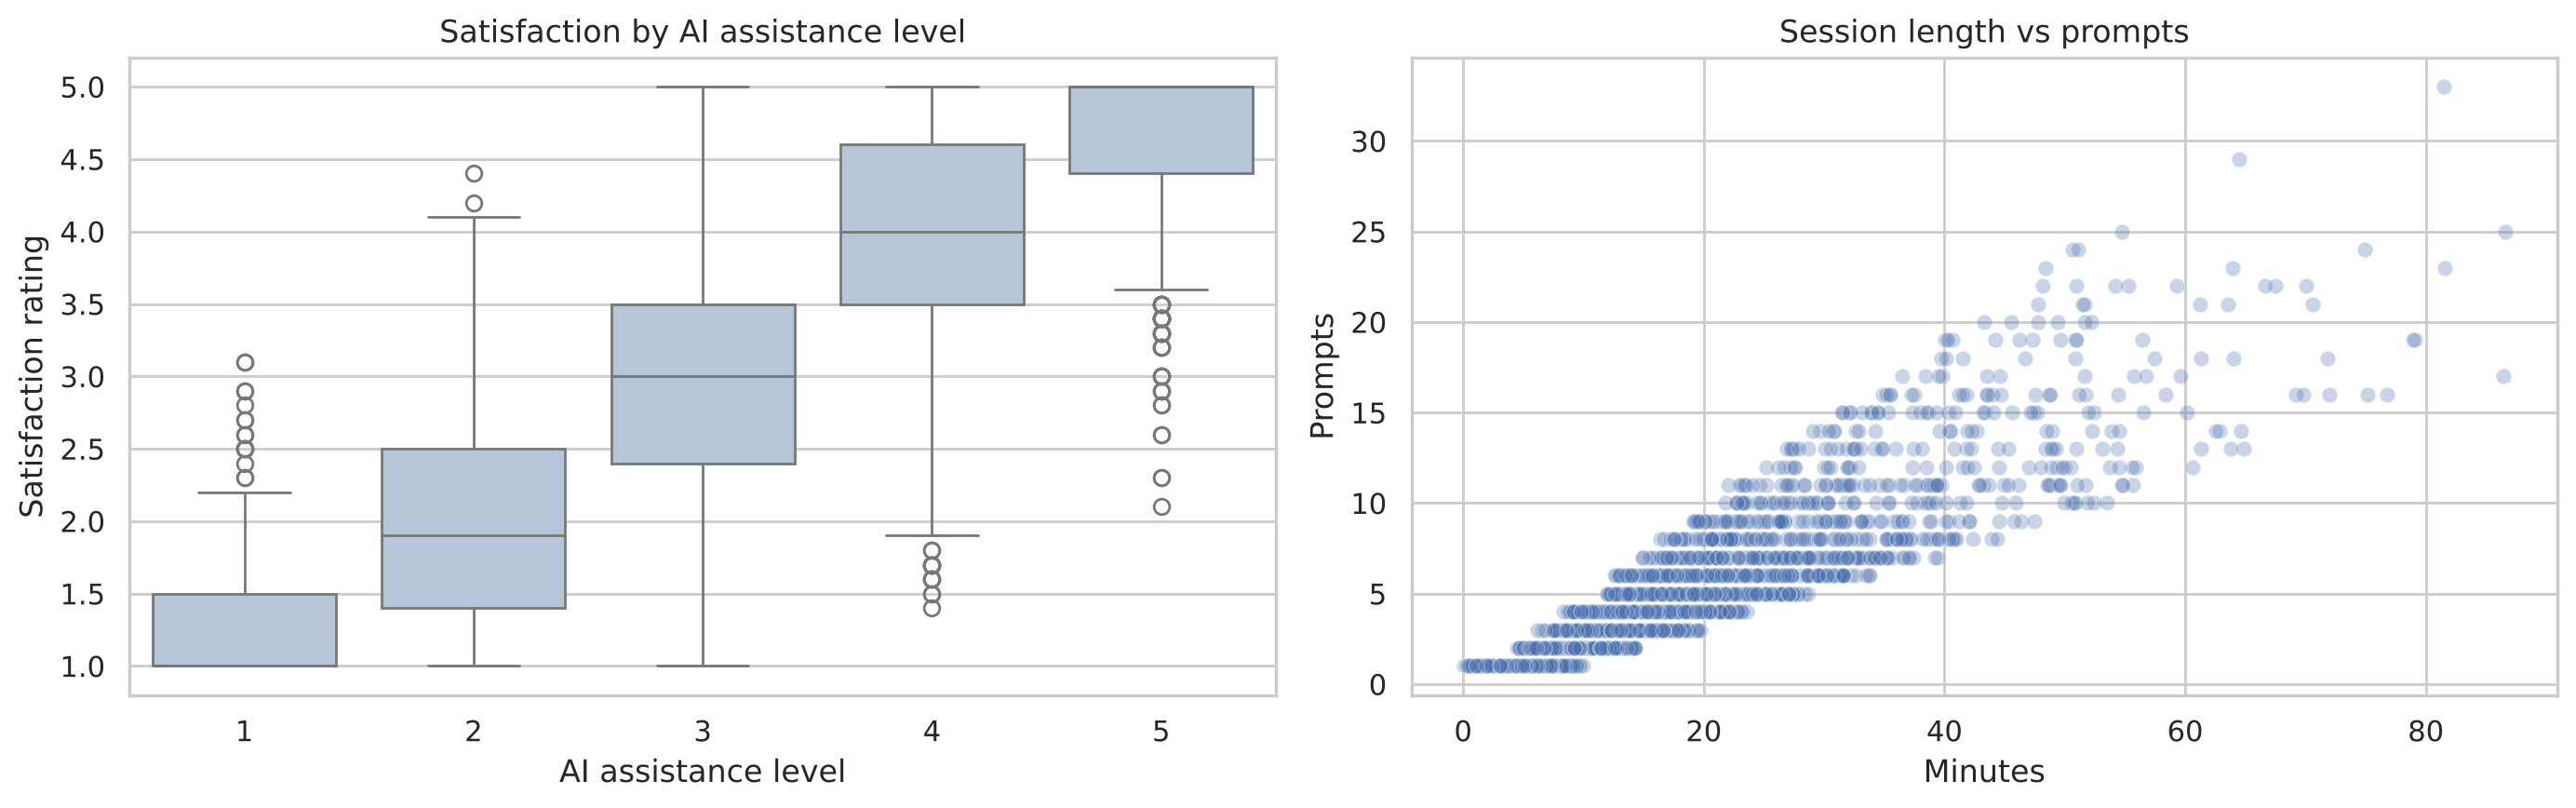

Spearman: AI assistance level vs satisfaction = 0.77  |  session length vs prompts = 0.93 (almost the same variable)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="AI_AssistanceLevel", y="SatisfactionRating", ax=axes[0], color="lightsteelblue")
axes[0].set(title="Satisfaction by AI assistance level", xlabel="AI assistance level", ylabel="Satisfaction rating")
sns.scatterplot(data=df.sample(2000, random_state=SEED), x="SessionLengthMin", y="TotalPrompts", alpha=0.3, ax=axes[1])
axes[1].set(title="Session length vs prompts", xlabel="Minutes", ylabel="Prompts")
plt.tight_layout(); plt.show()

r1 = stats.spearmanr(df["AI_AssistanceLevel"], df["SatisfactionRating"])[0]
r2 = stats.spearmanr(df["SessionLengthMin"], df["TotalPrompts"])[0]
print(f"Spearman: AI assistance level vs satisfaction = {r1:.2f}  |  session length vs prompts = {r2:.2f} (almost the same variable)")

### 3.2 What relates to reusing the assistant?

For every variable I report the reuse rate and a statistical test: **chi-square + Cramér's V** for categorical variables (effect size 0 = none, 1 = perfect) and **Spearman** for numeric ones. Bars show the reuse rate per group, the dashed line is the overall rate.

In [6]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2, p, *_ = stats.chi2_contingency(ct)
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), p

rows = []
for c in ["FinalOutcome", "TaskType", "Discipline", "StudentLevel"]:
    v, p = cramers_v(df[c], df["UsedAgain"]); rows.append({"variable": c, "test": "chi2 / Cramer's V", "effect": v, "p_value": p})
for c in ["SessionLengthMin", "TotalPrompts", "AI_AssistanceLevel", "SatisfactionRating"]:
    r, p = stats.spearmanr(df[c], df["UsedAgain"]); rows.append({"variable": c, "test": "Spearman |r|", "effect": abs(r), "p_value": p})
assoc = pd.DataFrame(rows).sort_values("effect", ascending=False).round(4)
assoc

,variable,test,effect,p_value
0,FinalOutcome,chi2 / Cramer's V,0.3709,0.0000
1,TaskType,chi2 / Cramer's V,0.0599,0.0000
2,Discipline,chi2 / Cramer's V,0.0271,0.2899
6,AI_AssistanceLevel,Spearman |r|,0.0095,0.3405
7,SatisfactionRating,Spearman |r|,0.0080,0.4258
5,TotalPrompts,Spearman |r|,0.0079,0.4302
3,StudentLevel,chi2 / Cramer's V,0.0079,0.7336
4,SessionLengthMin,Spearman |r|,0.0064,0.5231


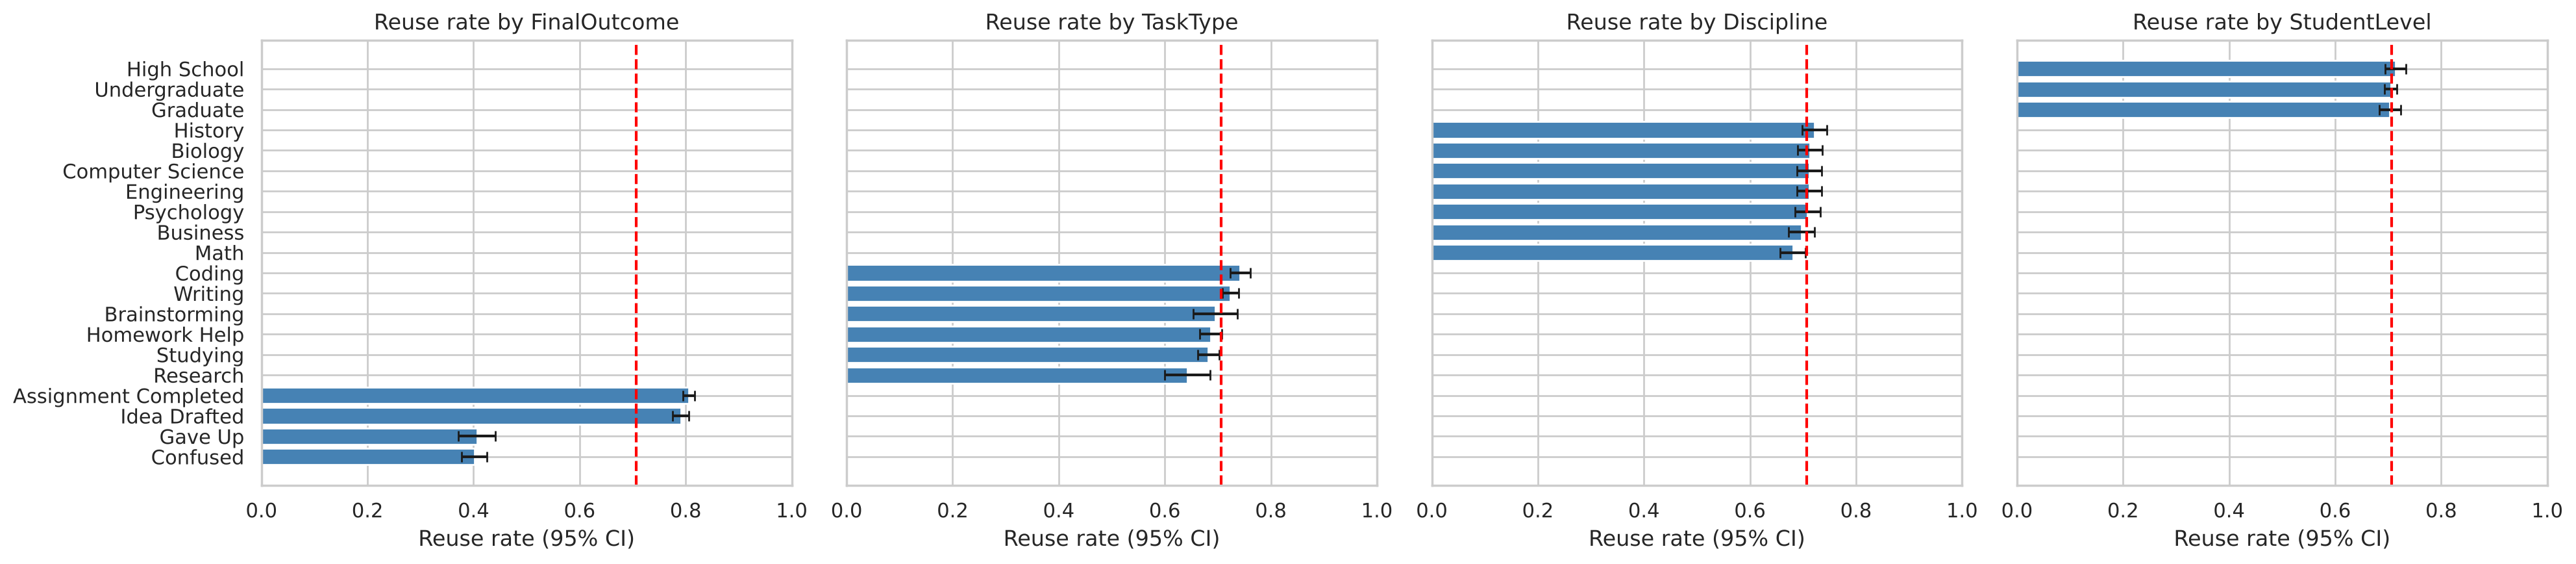

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, c in zip(axes, ["FinalOutcome", "TaskType", "Discipline", "StudentLevel"]):
    g = df.groupby(c)["UsedAgain"].agg(["mean", "count"]).sort_values("mean")
    se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"]) * 1.96
    ax.barh(g.index, g["mean"], xerr=se, color="steelblue", capsize=3)
    ax.axvline(base_rate, color="red", ls="--"); ax.set_title(f"Reuse rate by {c}"); ax.set_xlabel("Reuse rate (95% CI)"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

In [8]:
sat_bins = pd.cut(df["SatisfactionRating"], [0, 2, 3, 4, 5.01], labels=["1-2", "2-3", "3-4", "4-5"])
print("Reuse rate by satisfaction band (satisfaction does NOT predict reuse):")
print(df.groupby(sat_bins, observed=True)["UsedAgain"].agg(["mean", "count"]).round(3))

Reuse rate by satisfaction band (satisfaction does NOT predict reuse):
                     mean  count
SatisfactionRating              
1-2                 0.721   1377
2-3                 0.708   2292
3-4                 0.698   2958
4-5                 0.707   3373


## 4. Predictive modelling: can we predict reuse?

Setup: stratified 5-fold cross-validation, preprocessing inside a `Pipeline`, and **a dummy baseline** to compare against. Because 70.6% of sessions are reuse, plain accuracy and the F1 of the positive class are misleading; I report **ROC AUC** and **balanced accuracy** as well.

Three feature sets:
- **A. All features** (includes post-session information: `FinalOutcome`, `SatisfactionRating`).
- **B. Pre-session features only** (what is known before/while the session runs, no outcome or satisfaction).
- **C. `FinalOutcome` only.**

In [9]:
num_all = ["SessionLengthMin", "TotalPrompts", "AI_AssistanceLevel", "SatisfactionRating"]
cat_all = ["StudentLevel", "Discipline", "TaskType", "FinalOutcome"]
feature_sets = {
    "A. All features": (num_all, cat_all),
    "B. Pre-session only": (["SessionLengthMin", "TotalPrompts", "AI_AssistanceLevel"], ["StudentLevel", "Discipline", "TaskType"]),
    "C. FinalOutcome only": ([], ["FinalOutcome"]),
}
def make_pre(num, cat):
    t = []
    if num: t.append(("n", StandardScaler(), num))
    if cat: t.append(("c", OneHotEncoder(handle_unknown="ignore"), cat))
    return ColumnTransformer(t)

models = {
    "Dummy (always 'reuse')": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "balanced_accuracy", "roc_auc", "f1"]
rows = []
for fs, (num, cat) in feature_sets.items():
    for name, m in models.items():
        if fs != "A. All features" and name.startswith("Random"): continue   # keep the table readable
        res = cross_validate(Pipeline([("pre", make_pre(num, cat)), ("m", m)]), df[num + cat], df["UsedAgain"], cv=cv, scoring=scoring)
        rows.append({"features": fs, "model": name, **{s: res[f"test_{s}"].mean() for s in scoring}})
cv_table = pd.DataFrame(rows).round(3)
cv_table

,features,model,accuracy,balanced_accuracy,roc_auc,f1
0,A. All features,Dummy (always 'reuse'),0.706,0.500,0.500,0.828
1,A. All features,Logistic Regression,0.752,0.673,0.681,0.831
2,A. All features,Random Forest,0.745,0.648,0.677,0.830
3,A. All features,Gradient Boosting,0.747,0.659,0.678,0.830
4,B. Pre-session only,Dummy (always 'reuse'),0.706,0.500,0.500,0.828
5,B. Pre-session only,Logistic Regression,0.706,0.500,0.528,0.828
6,B. Pre-session only,Gradient Boosting,0.704,0.499,0.525,0.826
7,C. FinalOutcome only,Dummy (always 'reuse'),0.706,0.500,0.500,0.828
8,C. FinalOutcome only,Logistic Regression,0.752,0.673,0.678,0.831
9,C. FinalOutcome only,Gradient Boosting,0.752,0.673,0.678,0.831


**How to read this:** the dummy that always says "reuse" already gets accuracy 0.706 and an F1 of about 0.83, so models whose F1 is also about 0.83 add nothing. The informative columns are ROC AUC (0.5 = random) and balanced accuracy (0.5 = random).

## 5. Held-out test evaluation (feature set A, Logistic Regression)

Majority baseline accuracy: 0.707
Test accuracy: 0.743 | balanced accuracy: 0.662 | ROC AUC: 0.673

              precision    recall  f1-score   support

 won't reuse       0.58      0.47      0.52       587
  will reuse       0.79      0.86      0.82      1413

    accuracy                           0.74      2000
   macro avg       0.69      0.66      0.67      2000
weighted avg       0.73      0.74      0.73      2000



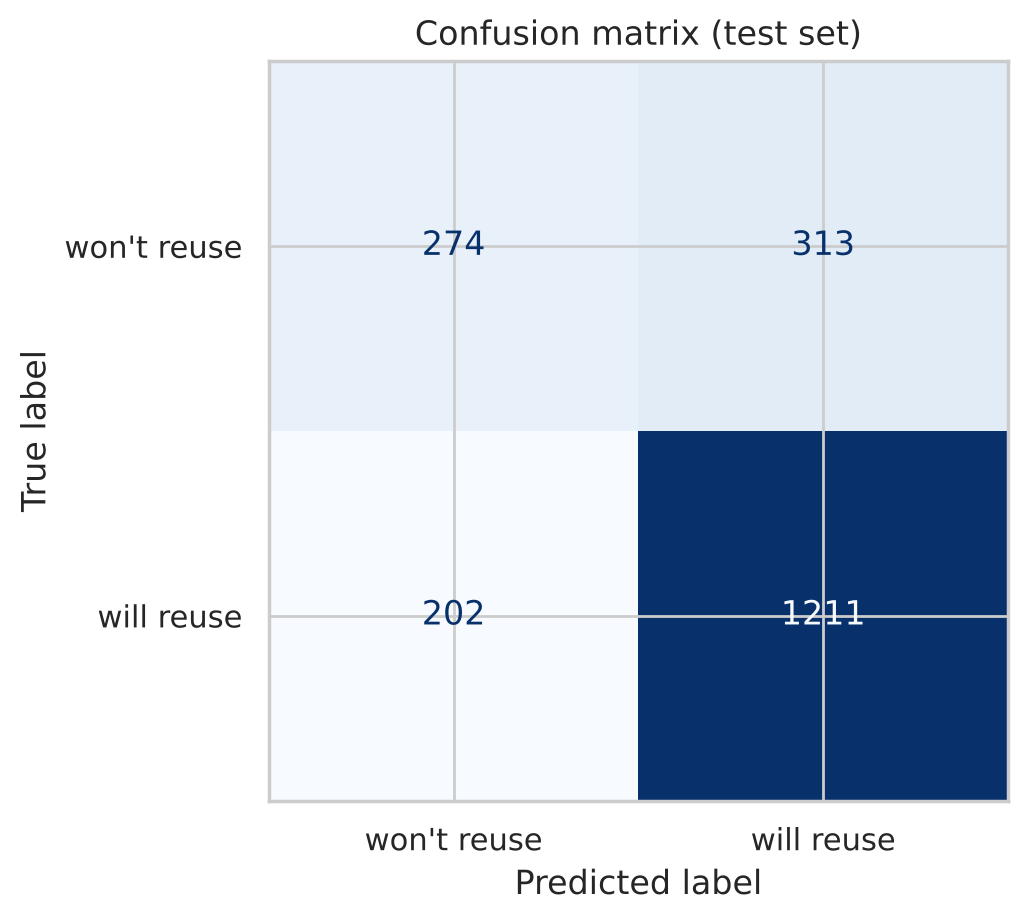

In [10]:
num, cat = feature_sets["A. All features"]
X, y = df[num + cat], df["UsedAgain"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
final = Pipeline([("pre", make_pre(num, cat)), ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(X_train, y_train)
pred, proba = final.predict(X_test), final.predict_proba(X_test)[:, 1]
print(f"Majority baseline accuracy: {1 - y_test.mean() if y_test.mean() < .5 else y_test.mean():.3f}")
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f} | balanced accuracy: {balanced_accuracy_score(y_test, pred):.3f} | ROC AUC: {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, pred, target_names=["won't reuse", "will reuse"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["won't reuse", "will reuse"], cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test set)"); plt.show()

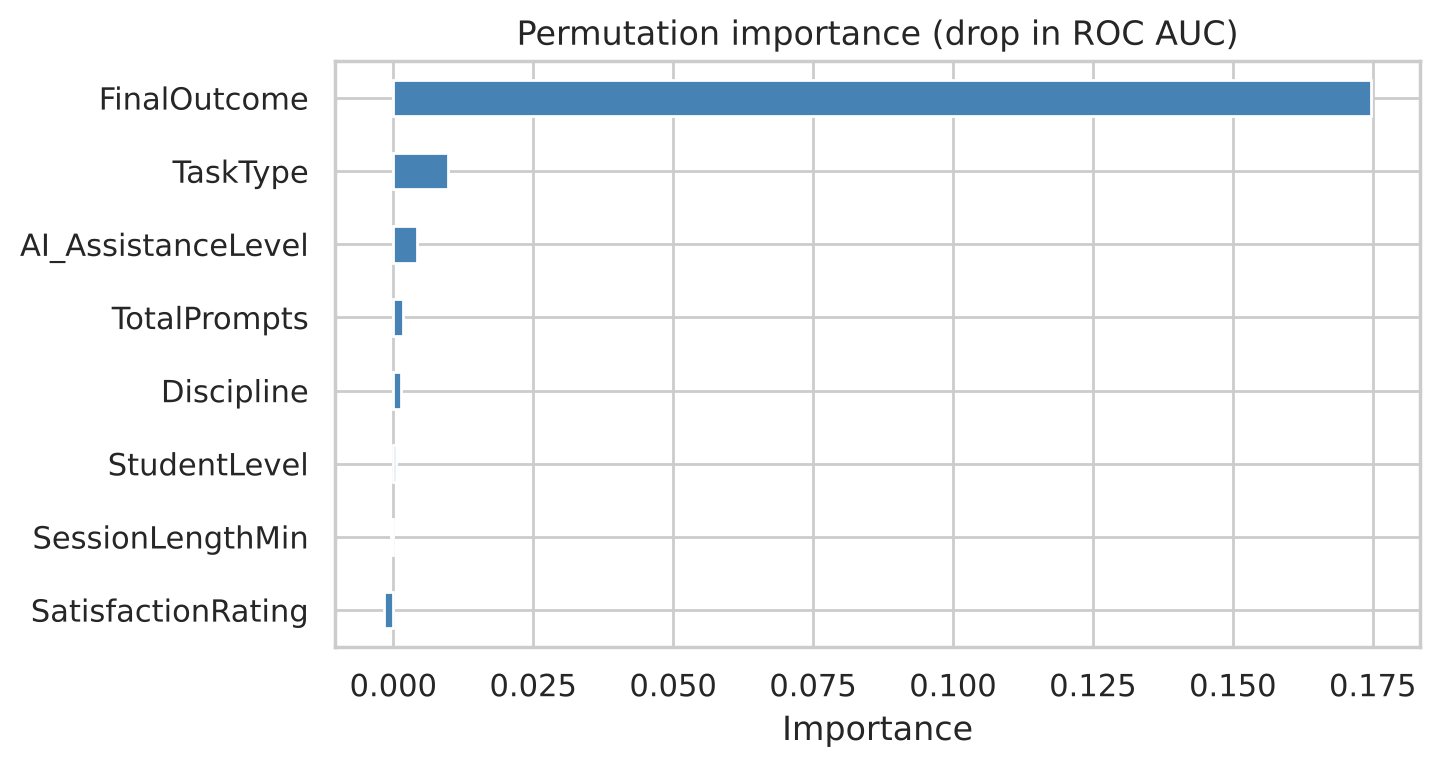

In [11]:
imp = permutation_importance(final, X_test, y_test, n_repeats=20, random_state=SEED, scoring="roc_auc")
imp_s = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp_s.plot.barh(figsize=(7, 3.8), color="steelblue")
plt.title("Permutation importance (drop in ROC AUC)"); plt.xlabel("Importance"); plt.show()

## 6. Conclusions

In [12]:
oc = df.groupby("FinalOutcome")["UsedAgain"].mean()
good, bad = oc[["Assignment Completed", "Idea Drafted"]].mean(), oc[["Confused", "Gave Up"]].mean()
A = cv_table[(cv_table.features == "A. All features") & (cv_table.model == "Logistic Regression")].iloc[0]
B = cv_table[(cv_table.features == "B. Pre-session only") & (cv_table.model == "Logistic Regression")].iloc[0]
print(f'''1. Reuse is {base_rate:.0%}; a model that always predicts "reuse" is already {base_rate:.0%} accurate. Accuracy alone says little.
2. The only variable clearly linked to reuse is FinalOutcome: ~{good:.0%} reuse after "Assignment Completed"/"Idea Drafted" vs ~{bad:.0%} after "Confused"/"Gave Up".
3. Student level, discipline, task type, session length, prompts, AI assistance level and even satisfaction show almost no relation to reuse (effects close to 0, see section 3.2).
4. Satisfaction follows the AI assistance level closely (Spearman {r1:.2f}) but does not translate into reuse.
5. Models using all features reach CV ROC AUC = {A.roc_auc:.2f} (accuracy {A.accuracy:.2f} vs baseline {base_rate:.2f}); using pre-session features only, AUC = {B.roc_auc:.2f}, i.e. no better than chance. Practically all predictive signal comes from FinalOutcome.
6. Removing IQR outliers would have deleted {len(df) - len(tmp)} valid rows, including answers on 1-5 rating scales, so it was not applied.

Limitations: the weak/absent relationships suggest the data may be simulated rather than real behaviour; findings are correlational, and FinalOutcome is only known after a session, so it cannot be used to predict reuse in advance.''')

1. Reuse is 71%; a model that always predicts "reuse" is already 71% accurate. Accuracy alone says little.
2. The only variable clearly linked to reuse is FinalOutcome: ~80% reuse after "Assignment Completed"/"Idea Drafted" vs ~40% after "Confused"/"Gave Up".
3. Student level, discipline, task type, session length, prompts, AI assistance level and even satisfaction show almost no relation to reuse (effects close to 0, see section 3.2).
4. Satisfaction follows the AI assistance level closely (Spearman 0.77) but does not translate into reuse.
5. Models using all features reach CV ROC AUC = 0.68 (accuracy 0.75 vs baseline 0.71); using pre-session features only, AUC = 0.53, i.e. no better than chance. Practically all predictive signal comes from FinalOutcome.
6. Removing IQR outliers would have deleted 861 valid rows, including answers on 1-5 rating scales, so it was not applied.

Limitations: the weak/absent relationships suggest the data may be simulated rather than real behaviour; findi